In [1]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.append("../py")
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False
ROOT = Path("..")

from prep import to_utf8, std_name, read_any, data_files, make_utf8_folder             # 프로젝트 폴더

In [9]:
import os, requests
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
URL = "http://apis.data.go.kr/1360000/AsosDalyInfoService/getWthrDataList"

rows = []
for y in range(2015, 2027):
    end = f"{y}1231" if y < 2026 else "20260630"
    r = requests.get(URL, params=dict(serviceKey=os.environ["DATA_GO_KR_KEY"], dataType="JSON",
                                      dataCd="ASOS", dateCd="DAY", startDt=f"{y}0101", endDt=end,
                                      stnIds="108", numOfRows=366, pageNo=1), timeout=60)
    items = r.json()["response"]["body"]["items"]["item"]
    rows += items
    print(y, len(items))                       # 평년 365, 윤년 366, 2026은 181

wx = pd.DataFrame(rows)                        # 모든 항목을 그대로 저장, 고르기는 1A-3에서
(ROOT / "data/raw/weather").mkdir(parents=True, exist_ok=True)
wx.to_csv(ROOT / "data/raw/weather/asos_daily_108_2015_202606.csv", index=False, encoding="utf-8")
wx.columns.tolist()

2015 365
2016 366
2017 365
2018 365
2019 365
2020 366
2021 365
2022 365
2023 365
2024 366
2025 365
2026 181


['stnId',
 'stnNm',
 'tm',
 'avgTa',
 'minTa',
 'minTaHrmt',
 'maxTa',
 'maxTaHrmt',
 'mi10MaxRn',
 'mi10MaxRnHrmt',
 'hr1MaxRn',
 'hr1MaxRnHrmt',
 'sumRnDur',
 'sumRn',
 'maxInsWs',
 'maxInsWsWd',
 'maxInsWsHrmt',
 'maxWs',
 'maxWsWd',
 'maxWsHrmt',
 'avgWs',
 'hr24SumRws',
 'maxWd',
 'avgTd',
 'minRhm',
 'minRhmHrmt',
 'avgRhm',
 'avgPv',
 'avgPa',
 'maxPs',
 'maxPsHrmt',
 'minPs',
 'minPsHrmt',
 'avgPs',
 'ssDur',
 'sumSsHr',
 'hr1MaxIcsrHrmt',
 'hr1MaxIcsr',
 'sumGsr',
 'ddMefs',
 'ddMefsHrmt',
 'ddMes',
 'ddMesHrmt',
 'sumDpthFhsc',
 'avgTca',
 'avgLmac',
 'avgTs',
 'minTg',
 'avgCm5Te',
 'avgCm10Te',
 'avgCm20Te',
 'avgCm30Te',
 'avgM05Te',
 'avgM10Te',
 'avgM15Te',
 'avgM30Te',
 'avgM50Te',
 'sumLrgEv',
 'sumSmlEv',
 'n99Rn',
 'iscs',
 'sumFogDur']

In [3]:
import os, requests
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
URL = "http://apis.data.go.kr/B090041/openapi/service/SpcdeInfoService/getRestDeInfo"

def get_holidays(year):
    out = []
    for m in range(1, 13):
        js = requests.get(URL, params=dict(serviceKey=os.environ["DATA_GO_KR_KEY"], solYear=year,
                                           solMonth=f"{m:02d}", _type="json", numOfRows=50), timeout=30).json()
        items = js["response"]["body"]["items"]
        if not items:                               # 그 달에 공휴일 없음 → 빈 문자열
            continue
        it = items["item"]
        it = [it] if isinstance(it, dict) else it   # 1건이면 리스트가 아니라 dict로 온다
        out += [{"date": pd.to_datetime(str(x["locdate"])), "name": x["dateName"]} for x in it]
    return out

holidays = pd.DataFrame([h for y in range(2016, 2027) for h in get_holidays(y)])
holidays.to_csv(ROOT / "data/raw/calendar/holidays_2016_2026.csv", index=False)
holidays.groupby(holidays.date.dt.year).size()

date
2016    18
2017    19
2018    18
2019    16
2020    18
2021    18
2022    19
2023    18
2024    19
2025    20
2026    22
dtype: int64

In [4]:
import shutil
from prep import make_utf8_folder

# 일별 대여건수, 이용정보(일별): CSV는 UTF-8 사본, 엑셀은 복사
for folder in ["rent_daily", "use_daily"]:
    print(folder)
    display(make_utf8_folder(ROOT / "data/raw" / folder, ROOT / f"data/interim/{folder}_utf8"))

# 고장신고: CSV 13개는 단계 0에서 이미 변환했다. 2015 ~ 2020.10 엑셀만 복사한다
for f in (ROOT / "data/raw/failure").glob("*.xlsx"):
    shutil.copy(f, ROOT / "data/interim/failure_utf8" / f.name)
    print("복사:", f.name)

rent_daily


,file,MB,how
0,대여소별 대여내역(2015년).xlsx,0.3,엑셀 → 복사
1,대여소별 대여내역(2016년).xlsx,2.6,엑셀 → 복사
2,대여소별 대여내역(2017년).xlsx,6.3,엑셀 → 복사
3,대여소별 반납내역(2015년).xlsx,0.3,엑셀 → 복사
4,대여소별 반납내역(2016년).xlsx,2.6,엑셀 → 복사
5,대여소별 반납내역(2017년).xlsx,6.3,엑셀 → 복사
6,서울특별시 공공자전거 일별 대여건수(2019.4~5).xlsx,0.0,엑셀 → 복사
7,서울특별시 공공자전거 일별 대여건수_2019.12.01~2020.05.31.csv,0.0,이름만 csv인 엑셀 → .xlsx로 복사
8,서울특별시 공공자전거 일별 대여건수_20190601_20191130.xlsx,0.0,엑셀 → 복사
9,서울특별시 공공자전거 일별 대여건수_2020.06.01~2020.06.30.csv,0.0,이름만 csv인 엑셀 → .xlsx로 복사


use_daily


,file,MB,how
0,2017년_자전거이용통계_일_1.csv,73.7,cp949
1,2017년_자전거이용통계_일_2.csv,79.3,cp949
2,2017년_자전거이용통계_일_3.csv,9.4,cp949
3,2018년_자전거이용통계_일_1.csv,82.0,cp949
4,2018년_자전거이용통계_일_2.csv,31.7,cp949
...,...,...,...
71,서울특별시 공공자전거 이용정보(일별)_2601.csv,110.1,cp949
72,서울특별시 공공자전거 이용정보(일별)_2602.csv,117.0,cp949
73,서울특별시 공공자전거 이용정보(일별)_2603.csv,173.2,cp949
74,서울특별시 공공자전거 이용정보(일별)_2604.csv,210.0,cp949


복사: 서울시 공공자전거 고장신고 내역_2015_2020.10.xlsx


In [2]:
rows = []
for f in data_files(ROOT / "data/interim/rent_daily_utf8"):
    x = read_any(f)
    dcol = next((c for c in x.columns if "일자" in c or "일시" in c or c in ("날짜", "일")), None)
    ncol = next((c for c in x.columns if "건수" in c), None)
    dt = pd.to_datetime(x[dcol].astype(str).str[:10], errors="coerce", format="mixed") if dcol else pd.Series(dtype="datetime64[ns]")
    n = pd.to_numeric(x[ncol].astype(str).str.replace(",", ""), errors="coerce") if ncol else pd.Series(dtype=float)
    rows.append({"file": f.name, "rows": len(x), "date_col": dcol, "count_col": ncol,
                 "first": dt.min(), "last": dt.max(), "n_dates": dt.nunique(),
                 "missing_in_file": (dt.max() - dt.min()).days + 1 - dt.nunique() if dcol else None,
                 "rows_per_date": round(len(x) / max(dt.nunique(), 1), 1),
                 "total": n.sum(), "cols": " | ".join(x.columns)})
chk = pd.DataFrame(rows).sort_values(["first", "file"]).reset_index(drop=True)
chk["gap_days"] = (chk["first"] - chk["last"].shift()).dt.days - 1
pd.set_option("display.max_colwidth", 60)
chk.drop(columns="cols")

서울특별시 공공자전거 일별 대여건수(2019.4~5).xlsx: 시트 3개 ['Sheet1', 'Sheet2', 'Sheet3'] → 합침


,file,rows,date_col,count_col,first,last,n_dates,missing_in_file,rows_per_date,total,gap_days
0,대여소별 대여내역(2015년).xlsx,12474,대여 일자 / 월,대여 건수,2015-09-19,2015-12-31,104,0,119.9,113708.0,NaN
1,대여소별 반납내역(2015년).xlsx,12474,반납 일자 / 월,반납 건수,2015-09-19,2015-12-31,104,0,119.9,113708.0,-104.0
2,대여소별 대여내역(2016년).xlsx,99829,대여 일자 / 월,대여 건수,2016-01-01,2016-12-31,366,0,272.8,1611635.0,0.0
3,대여소별 반납내역(2016년).xlsx,99829,반납 일자 / 월,반납 건수,2016-01-01,2016-12-31,366,0,272.8,1611635.0,-366.0
4,대여소별 대여내역(2017년).xlsx,245446,대여 일자 / 월,대여 건수,2017-01-01,2017-12-31,365,0,672.5,5031031.0,0.0
5,대여소별 반납내역(2017년).xlsx,245446,반납 일자 / 월,반납 건수,2017-01-01,2017-12-31,365,0,672.5,5031031.0,-365.0
6,서울특별시_공공자전거 일별 대여건수_(2018~2019.03).csv,455,대여일자,대여건수,2018-01-01,2019-03-31,455,0,1.0,11996809.0,0.0
7,서울특별시 공공자전거 일별 대여건수(2019.4~5).xlsx,61,대여일자,대여건수,2019-04-01,2019-05-31,61,0,1.0,3700895.0,0.0
8,서울특별시 공공자전거 일별 대여건수_20190601_20191130.xlsx,182,대여일시,대여건수,2019-06-01,2019-11-30,182,1,1.0,12617041.0,0.0
9,서울특별시 공공자전거 일별 대여건수_2019.12.01~2020.05.31.xlsx,183,대여일시,대여건수,2019-12-01,2020-05-31,183,0,1.0,8609769.0,0.0


In [3]:
names = [f.name for f in data_files(ROOT / "data/interim/use_daily_utf8")]
print(len(names), "개")
print(*names[-8:], sep="\n")

82 개
서울특별시 공공자전거 이용정보(일별)_2604.csv
서울특별시 공공자전거 이용정보(일별)_2605.csv
서울특별시 공공자전거 이용정보_2019.10.csv
서울특별시 공공자전거 이용정보_2019.11.csv
서울특별시 공공자전거 이용정보_2019.6.csv
서울특별시 공공자전거 이용정보_2019.7.csv
서울특별시 공공자전거 이용정보_2019.8.csv
서울특별시 공공자전거 이용정보_2019.9.csv


In [4]:
from prep import std_name, read_any

def read_fail(path):
    x = read_any(path)
    x = std_name(x, "bike_no", ["자전거번호"])
    x = std_name(x, "reg_dt", ["등록일시"])
    x = std_name(x, "kind", ["고장구분", "구분"])
    return x[["bike_no", "reg_dt", "kind"]].assign(src=Path(path).name)

files = data_files(ROOT / "data/interim/failure_utf8")          # .DS_Store 같은 숨김 파일 제외
fail = pd.concat([read_fail(f) for f in files], ignore_index=True)

# 파일에서 마지막 날이 통째로 빠진 6일(2020-10-31, 2021-01-31, 2021-06-30, 2021-12-31, 2022-06-30, 2022-12-31)은
# Open API로 받아 둔 실제 신고로 채운다(py/failure_gaps.py가 만든 파일). API와 파일은 같은 데이터다:
# 함께 받아 둔 '다음 날' 행 수가 파일과 6일 모두 완전히 같다(예: 2021-07-01 둘 다 821행).
gap = pd.read_csv(ROOT / "data/raw/failure_api/failure_gap_days.csv", dtype=str)
gap = gap[gap.is_gap == "True"][["bike_no", "reg_dt", "kind"]].assign(src="api_gap_days")
fail = pd.concat([fail, gap], ignore_index=True)
print("API로 채운 행:", len(gap))
fail["bike"]   = fail.bike_no.str.extract(r"(\d+)", expand=False).astype("Int64")
fail["reg_ts"] = pd.to_datetime(fail.reg_dt, format="mixed", errors="coerce")   # 한국 시간 그대로(시간대 없음)
fail["date"]   = fail.reg_ts.dt.normalize()
fail["kind"]   = fail.kind.str.replace(r"\s+", " ", regex=True).str.strip()

fail.kind.value_counts()                                  # 고장구분 실제 값 목록부터 확인
fail.reg_ts.isna().sum(), fail.bike.isna().sum()          # 파싱 실패 수

API로 채운 행: 1372


(np.int64(0), np.int64(0))

In [5]:
# 단계 0 확인: 2021-02 ~ 2021-12 파일만 날짜만 있다(나머지는 시각 있음) → 파일 단위가 아니라 행 단위로 판단
fail["has_time"] = fail.reg_dt.str.contains(":", na=False)

fail = fail.sort_values(["bike", "kind", "reg_ts"])
gap_h = fail.groupby(["bike", "kind"]).reg_ts.diff().dt.total_seconds() / 3600
dedup_h = np.where(fail.has_time, 48, 24)          # 날짜만 있으면 '같은 날·다음 날'
fail["keep"] = gap_h.isna() | (gap_h > dedup_h)

1 - fail.keep.mean()        # 병합으로 빠지는 비율 → 결정 로그에 기록

np.float64(0.030980353324463805)

In [6]:
kind_map = {"타이어": "tire", "체인": "chain", "안장": "saddle", "페달": "pedal",
            "단말기": "terminal", "잠금장치 불량": "lock", "파손": "broken", "기타": "etc"}

def to_daily(df, prefix):
    k = df.kind.map(kind_map).fillna("etc")
    return (df.assign(k=k).groupby(["date", "k"]).size()
              .unstack(fill_value=0).add_prefix(prefix).reset_index())

daily_fail  = to_daily(fail, "fail_")
daily_faild = to_daily(fail[fail.keep], "faild_")     # 중복 병합 버전

In [7]:
daily_report = (fail.drop_duplicates(["bike", "reg_ts"]).groupby("date").size()
                    .rename("reports").reset_index())       # 전체 신고 건수(주 타깃 후보)

## 노출 1 — 일별 대여건수 (`rentals`)

'노출'은 고장신고율의 분모다(얼마나 많이 탔는가). 첫 번째 후보는 하루 대여 건수다.

- 2015~2017년은 '대여소별 대여내역'과 '대여소별 반납내역' 두 종류가 있다. 같은 이용을 빌린 쪽·반납한 쪽에서 각각 센 것이라
  연 합계가 완전히 같다(2016년 둘 다 1,611,635). 둘 다 읽으면 2배가 되므로 **반납내역은 읽지 않는다**(결정 2026-10-05).
- 숫자에 쉼표가 든 파일(`"105,196"`)과 끝에 빈 줄이 붙은 파일(2021~2022)이 있어 읽을 때 정리한다.

In [8]:
def read_rent_daily(path):
    """일별 대여건수 파일 하나 → (date, rentals) 표. 파일마다 다른 열 이름을 같은 이름으로 맞춘다"""
    x = read_any(path)
    x = std_name(x, "date_raw", ["대여일자", "대여일시", "대여 일자 / 월"])
    x = std_name(x, "n", ["대여건수", "대여 건수"])
    return pd.DataFrame({"date": pd.to_datetime(x.date_raw.astype(str).str[:10], errors="coerce"),
                         "rentals": pd.to_numeric(x.n.astype(str).str.replace(",", ""), errors="coerce")}   # "105,196" → 105196
                        ).dropna(subset=["date"])                                                          # 파일 끝의 빈 줄 제거

rent_files = [f for f in data_files(ROOT / "data/interim/rent_daily_utf8") if "반납내역" not in f.name]     # 반납내역 3개 제외
# 2015~2017 파일은 대여소×날짜 단위라 날짜별로 더해야 하루 합계가 된다(다른 해는 이미 하루 한 줄)
rent_daily = (pd.concat([read_rent_daily(f) for f in rent_files])
                .groupby("date", as_index=False).rentals.sum())

print(len(rent_files), "개 파일,", rent_daily.date.min().date(), "~", rent_daily.date.max().date())
full = pd.date_range("2016-01-01", "2026-06-30")
print("2016년 이후 빠진 날:", [str(d.date()) for d in full.difference(rent_daily.date)])   # 2019-09-07 하루여야 한다
rent_daily.groupby(rent_daily.date.dt.year).rentals.sum().astype(int)                       # 연도별 합계

서울특별시 공공자전거 일별 대여건수(2019.4~5).xlsx: 시트 3개 ['Sheet1', 'Sheet2', 'Sheet3'] → 합침
20 개 파일, 2015-09-19 ~ 2026-06-30
2016년 이후 빠진 날: ['2019-09-07']


date
2015      113708
2016     1611635
2017     5031031
2018    10124874
2019    19071949
2020    23705020
2021    32054693
2022    40950815
2023    44905293
2024    43849586
2025    37373092
2026    17978991
Name: rentals, dtype: int64

## 노출 2·3 — 이동거리 (`dist_km`), 이용시간 (`use_hours`)

두 출처를 쓴다. 둘 다 파일이 커서(합계 약 80GB) 날짜별 합계를 만드는 일은 스크립트로 따로 해 두었고, 여기서는 그 결과만 읽는다.

| 출처 | 만든 스크립트 | 특징 |
|---|---|---|
| 이용정보(일별) | `py/build/use_daily.py` | 서울시가 미리 더해 둔 요약본. **기본으로 쓴다.** 구멍이 있다(2016년 없음, 2022-05 없음, 엑셀 줄 수 한계로 잘린 파일 4개 등) |
| 대여이력(건별) | `py/build/rent_history_daily.py` | 대여 한 건이 한 줄인 원본. 구멍 난 날을 메우는 데 쓴다 |

**메우는 규칙**: 이용정보에 그 날이 없거나, 이용정보의 이용건수가 일별 대여건수와 1% 넘게 다르면 그 날은 대여이력 값으로 바꾼다.
두 출처가 모두 멀쩡한 날에는 거리·시간 합계가 소수 넷째 자리까지 같으므로 섞어 써도 된다.

In [9]:
# 이용정보(일별): 파일×날짜별 합계 → 날짜별 합계
use = (pd.read_parquet(ROOT / "data/interim/use_daily_agg/use_daily_by_file.parquet")
         .groupby("date", as_index=False)[["n_use", "dist_m", "min_use"]].sum())
# 대여이력: 날짜별 합계. dist_zero = 그날 '이용거리가 0으로 기록된 대여' 건수(거리 기록 품질을 보는 데 쓴다)
hist = pd.read_parquet(ROOT / "data/interim/rent_hist_daily/rent_hist_daily.parquet").drop(columns="ym")

u = (pd.DataFrame({"date": pd.date_range("2016-01-01", "2026-06-30")})
       .merge(rent_daily, on="date", how="left")
       .merge(use, on="date", how="left")
       .merge(hist.add_prefix("h_").rename(columns={"h_date": "date"}), on="date", how="left"))

# 이용정보를 믿을 수 없는 날: 값이 없거나, 이용건수가 일별 대여건수와 1% 넘게 다르다
bad = u.n_use.isna() | ((u.n_use / u.rentals - 1).abs() > 0.01)
patch = bad & u.h_n_use.notna()                       # 그중 대여이력으로 메울 수 있는 날
u["use_src"] = np.where(patch, "rent_history", np.where(u.n_use.notna(), "use_daily", "none"))   # 어느 출처 값을 썼는지
for c in ("n_use", "dist_m", "min_use"):
    u[c] = np.where(patch, u["h_" + c], u[c])

u["dist_km_raw"] = u.dist_m / 1000                    # 기록된 그대로의 이동거리 합(km)
u["use_hours"] = u.min_use / 60                       # 이용시간 합(시간)
u["dist_zero_share"] = u.h_dist_zero / u.h_n_use      # 그날 대여 중 거리가 0으로 기록된 비율(대여이력 기준)

print("출처별 일수:", u.use_src.value_counts().to_dict())
print("메운 뒤에도 이용건수가 대여건수와 1% 넘게 다른 날:", int(((u.n_use / u.rentals - 1).abs() > 0.01).sum()))
# 대여이력으로 메운 날이 어느 달에 며칠씩인지
u[patch].groupby(u.date.dt.to_period("M")).size().rename("메운 일수").to_frame().T

출처별 일수: {'use_daily': 3269, 'rent_history': 564, 'none': 1}
메운 뒤에도 이용건수가 대여건수와 1% 넘게 다른 날: 2


date,2016-01,2016-02,2016-03,2016-04,2016-05,2016-06,2016-07,2016-08,2016-09,2016-10,...,2019-02,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2022-05,2025-02
메운 일수,31,29,31,30,31,30,31,31,30,31,...,1,4,31,28,31,30,31,6,31,1


### 이동거리 기록 품질

대여 한 건마다 기록되는 이용거리가 **0으로 찍힌 비율**이 시기에 따라 크게 다르다. 평소 1~4%인데,
2020년 3월부터 늘어 2020년 8~12월에는 약 90%가 0이고 2021-01-05에 갑자기 정상으로 돌아온다(원본 자체의 문제라 복구할 수 없다).
2021-08 ~ 2022-03에도 11~22%로 높다.

그래서 거리는 세 열로 나눠 둔다.

- `dist_km_raw`: 기록된 그대로
- `dist_ok`: 그날 거리 0 비율이 10% 미만이면 True **(10%는 임시 기준. 확정은 사람이 한다)**
- `dist_km`: `dist_ok`인 날만 값이 있고 나머지는 빈칸 → 모형에서 거리를 노출로 쓰면 그 날들은 자동으로 빠진다

어떤 노출(대여건수·이용시간·이동거리)을 최종으로 쓸지는 단계 1B에서 비교한 뒤 정한다.

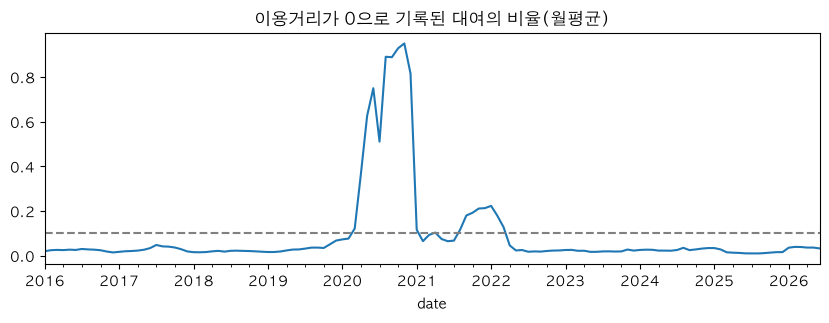

dist_ok가 아닌 날: 562 일


date,2017-07,2019-09,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,...,2021-05,2021-08,2021-09,2021-10,2021-11,2021-12,2022-01,2022-02,2022-03,2022-04
zero_share,0.048,0.036,0.121,0.367,0.626,0.75,0.51,0.89,0.889,0.929,...,0.074,0.116,0.179,0.192,0.211,0.213,0.223,0.179,0.128,0.045
ok_days,30.000,29.000,3.000,0.000,0.000,0.00,0.00,0.00,0.000,0.000,...,28.000,18.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,25.000
days,31.000,30.000,31.000,30.000,31.000,30.00,31.00,31.00,30.000,31.000,...,31.000,31.000,30.000,31.000,30.000,31.000,31.000,28.000,31.000,30.000


In [10]:
DIST_ZERO_MAX = 0.10                                   # 임시 기준: 거리 0 비율이 이 값 이상이면 그날 거리 합계를 쓰지 않는다
u["dist_ok"] = u.dist_zero_share < DIST_ZERO_MAX
u["dist_km"] = u.dist_km_raw.where(u.dist_ok)

q = u.groupby(u.date.dt.to_period("M")).agg(zero_share=("dist_zero_share", "mean"), ok_days=("dist_ok", "sum"), days=("date", "size"))
ax = q.zero_share.plot(figsize=(10, 3), title="이용거리가 0으로 기록된 대여의 비율(월평균)")
ax.axhline(DIST_ZERO_MAX, color="gray", ls="--"); plt.show()
print("dist_ok가 아닌 날:", int((~u.dist_ok).sum()), "일")
q[q.ok_days < q.days].round(3).T                       # 거리를 못 쓰는 날이 있는 달

In [11]:
use_daily = u[["date", "n_use", "dist_km", "dist_km_raw", "use_hours", "dist_zero_share", "dist_ok", "use_src"]]

## 기상 (ASOS 서울 108 지점 일자료)

API가 주는 62개 열 중 분석에 쓸 16개만 골라 알아보기 쉬운 이름을 붙인다. 빈칸의 뜻이 열마다 다르다.

- 강수·적설 열의 빈칸 = 비·눈이 없었다는 뜻 → 합칠 때 0으로 채운다
- 기온·습도·일사·바람 열의 빈칸 = 진짜 결측(관측 누락) → 앞뒤 날 값을 직선으로 이어 채우고(선형 보간) 채운 날을 표시한다

In [12]:
ASOS_API = {"tm": "date",
            "avgTa": "tavg", "maxTa": "tmax", "minTa": "tmin",                 # 평균·최고·최저기온(℃)
            "sumRn": "rain_mm", "hr1MaxRn": "rain_1h_max", "sumRnDur": "rain_dur_h",   # 일강수량(mm), 1시간 최다강수(mm), 강수 계속시간(시간)
            "avgRhm": "humidity", "minRhm": "hum_min",                         # 평균·최소 상대습도(%)
            "sumGsr": "solar", "sumSsHr": "sunshine",                          # 일사량(MJ/m²), 일조시간(시간)
            "avgWs": "wind_avg", "maxWs": "wind_max",                          # 평균·최대 풍속(m/s)
            "avgTs": "ground_temp", "minTg": "grass_tmin",                     # 평균 지면온도, 최저 초상온도(℃)
            "ddMefs": "snow_cm", "ddMes": "snow_depth_cm"}                     # 그날 새로 온 눈, 쌓인 눈 전체(cm)

raw = pd.read_csv(ROOT / "data/raw/weather/asos_daily_108_2015_202606.csv", dtype=str)
asos = raw[list(ASOS_API)].rename(columns=ASOS_API)
asos["date"] = pd.to_datetime(asos["date"])
num = asos.columns.drop("date")
asos[num] = asos[num].apply(pd.to_numeric, errors="coerce")      # 빈 문자열 → NaN(빈칸)

print(len(asos), asos.date.min().date(), "~", asos.date.max().date())   # 4,199행, 2015-01-01 ~ 2026-06-30
asos[asos.date >= "2016-01-01"].isna().sum().rename("빈칸 일수(2016~)").to_frame().T

4199 2015-01-01 ~ 2026-06-30


,date,tavg,tmax,tmin,rain_mm,rain_1h_max,rain_dur_h,humidity,hum_min,solar,sunshine,wind_avg,wind_max,ground_temp,grass_tmin,snow_cm,snow_depth_cm
빈칸 일수(2016~),0,0,1,1,2294,2844,2292,0,1,18,17,8,6,0,2,3702,3613


## 합치기와 파생변수

2016-01-01 ~ 2026-06-30의 모든 날짜(3,834일)를 한 줄씩 깔고, 날짜를 기준으로 노출·기상·고장신고를 옆에 붙인다.

In [13]:
m = pd.DataFrame({"date": pd.date_range("2016-01-01", "2026-06-30")})        # 3,834일
for part in (rent_daily, use_daily, asos, daily_fail, daily_faild, daily_report):
    m = m.merge(part, on="date", how="left")

# 고장신고: 그날 신고가 없으면 빈칸이 되므로 0으로 채운다
fail_cols = [c for c in m if c.startswith(("fail_", "faild_"))]
m[fail_cols] = m[fail_cols].fillna(0).astype(int)
m["reports"] = m["reports"].fillna(0).astype(int)

# 기상: 강수·적설 빈칸 = 없었음 → 0
zero_cols = ["rain_mm", "rain_1h_max", "rain_dur_h", "snow_cm", "snow_depth_cm"]
m[zero_cols] = m[zero_cols].fillna(0)
# 기상: 나머지 빈칸은 진짜 결측 → 선형 보간(앞뒤 날 값을 직선으로 이음). 채운 날은 wx_imputed = True
# (가장 많은 일사량도 18일, 연속으로는 최대 2일이라 채우는 방식에 따른 차이는 거의 없다)
wx_cols = ["tavg", "tmax", "tmin", "humidity", "hum_min", "solar", "sunshine", "wind_avg", "wind_max",
           "ground_temp", "grass_tmin"]
m["wx_imputed"] = m[wx_cols].isna().any(axis=1)
m[wx_cols] = m[wx_cols].interpolate(limit_direction="both")
print("기상값을 채운 날:", int(m.wx_imputed.sum()), "일")

기상값을 채운 날: 27 일


In [14]:
# --- 운영이 멈췄던 날 표시 --------------------------------------------------------------------
# 근거: 서울시 공지·기사(data/raw/external/events.csv) + 대여이력의 시간대별 대여 건수로 시각까지 확인.
# 이런 날을 그대로 두면 모형이 "비가 오면 대여가 0이 된다"처럼 날씨 효과로 잘못 배운다. 그래서 표시해 두고 분석에서 뺄 수 있게 한다.

# (1) no_service: 하루 종일 사실상 운영하지 않은 날 → 신고율(신고 ÷ 노출) 분석·모형에서 뺀다
#     2017-07-06  시스템 개편(07-05 12시 ~ 07-07 12시 중단). 대여 9건
#     2019-09-07  태풍 링링(09-06 12시 ~ 09-08 11시 중단). 대여 기록 없음
#     2022-08-09  기록적 폭우로 대여 중단(08-08 낮 ~ 08-10 새벽). 대여 482건(평소 약 10만 건)
NO_SERVICE = ["2017-07-06", "2019-09-07", "2022-08-09"]
m["no_service"] = m.date.isin(pd.to_datetime(NO_SERVICE))

# (2) partial_service: 하루 중 일부 시간만 운영한 날 → 값은 실제 그대로 두고 표시만 한다
#     2017-07-05, 07-07   시스템 개편 중단의 시작·끝 날
#     2019-09-06, 09-08   태풍 링링 중단의 시작·끝 날
#     2020-08-26, 08-27   태풍 바비(08-26 18시 중단 ~ 08-27 14시대 재개)
#     2022-08-08          폭우(12시대부터 대여 급감)
#     2023-09-07          앱·서버 접속 장애(08 ~ 10시대 대여 거의 없음)
#     2024-06-29, 06-30   06-29 19시 ~ 06-30 오전 대여 급감(06-28 ~ 30 DDoS 공격 기간과 겹침. 비도 왔다)
PARTIAL_SERVICE = ["2017-07-05", "2017-07-07", "2019-09-06", "2019-09-08", "2020-08-26", "2020-08-27",
                   "2022-08-08", "2023-09-07", "2024-06-29", "2024-06-30"]
m["partial_service"] = m.date.isin(pd.to_datetime(PARTIAL_SERVICE))

# 2019-09-07은 두 출처 모두 그날 행이 없어 빈칸이다. 자료 누락이 아니라 실제로 대여가 없던 날이므로 보간하지 않고 0으로 둔다
m.loc[m.date == "2019-09-07", ["rentals", "n_use", "dist_km", "dist_km_raw", "use_hours"]] = 0

# (3) report_anomaly: 대여는 정상인데 신고만 비정상적으로 적은 기간 → 표시만 한다(쓸지 말지는 분석 단계에서 정한다)
#     2023-09-07 ~ 10-10: 09-07 접속 장애 직후부터 신고율이 약 40% 낮다(대여 만 건당 40 안팎 → 22 안팎, 모든 부품 공통).
#     10-11부터 원래 수준. 장애 뒤 한동안 신고가 덜 접수된 것으로 보인다(원인 공지는 못 찾음)
m["report_anomaly"] = m.date.between("2023-09-07", "2023-10-10")

m[m.no_service | m.partial_service][["date", "rentals", "use_hours", "reports", "no_service", "partial_service"]]

,date,rentals,use_hours,reports,no_service,partial_service
551,2017-07-05,5222.0,1748.766667,8,False,True
552,2017-07-06,9.0,1.533333,0,True,False
553,2017-07-07,3245.0,1178.400000,5,False,True
1344,2019-09-06,16631.0,5003.216667,98,False,True
1345,2019-09-07,0.0,0.000000,2,True,False
1346,2019-09-08,52055.0,31188.033333,260,False,True
1699,2020-08-26,40169.0,16004.133333,64,False,True
1700,2020-08-27,32745.0,16720.683333,52,False,True
2411,2022-08-08,21616.0,6558.300000,70,False,True
2412,2022-08-09,482.0,109.366667,1,True,False


In [15]:
# --- 고장신고 합계 ------------------------------------------------------------------------
m["total_rows"] = m.filter(regex=r"^fail_").sum(axis=1)   # 행 수(신고×유형) 합계 = 서울시 공표치와 같은 기준
m["total_faults"] = m["reports"]                          # 신고 건수(고유 자전거+일시) = 전체 고장의 주 타깃(단계 0 결정)

# --- 달력 ---------------------------------------------------------------------------------
hol = pd.read_csv(ROOT / "data/raw/calendar/holidays_2016_2026.csv", parse_dates=["date"])
m["year"], m["month"], m["doy"] = m.date.dt.year, m.date.dt.month, m.date.dt.dayofyear     # doy = 1월 1일부터 몇 번째 날
m["dow"] = m.date.dt.dayofweek + 1                        # 요일: 1 = 월 … 7 = 일
m["is_weekend"] = m.dow >= 6
m["is_holiday"] = m.date.isin(hol.date)
m["is_off"] = m.is_weekend | m.is_holiday                 # 쉬는 날(주말 또는 공휴일)
prev_off = m.is_off.shift(1, fill_value=False)            # 어제가 쉬는 날이었나
next_off = m.is_off.shift(-1, fill_value=False)           # 내일이 쉬는 날인가
m["after_off"] = ~m.is_off & prev_off                     # 쉬는 날 다음 첫 근무일(보통 월요일): 밀린 신고가 몰리는지 보려고
m["bridge"] = ~m.is_off & prev_off & next_off             # 징검다리 근무일(쉬는 날 사이에 낀 하루)

# --- 날씨 파생 ----------------------------------------------------------------------------
m["rain_any"] = m.rain_mm >= 1                            # 비 온 날(1mm 이상)
m["rain_lag1"], m["rain_lag2"] = m.rain_mm.shift(1), m.rain_mm.shift(2)       # 어제·그제 강수량: '비 온 다음 날' 효과용
m["days_since_rain"] = m.groupby(m.rain_any.cumsum()).cumcount().clip(upper=14)   # 마지막 비 이후 며칠째(최대 14)
m["temp_range"] = m.tmax - m.tmin                         # 일교차
m["freeze_thaw"] = (m.tmin < 0) & (m.tmax > 0)            # 얼었다 녹은 날
m["hot"], m["cold"] = m.tmax >= 30, m.tmin <= -5          # 더운 날·추운 날 더미. hot은 EDA에서 효과가 안 보였지만 일단 모형에 넣어 보고 성능으로 판단한다. cold는 아래 cold_wave·winter_anom으로 대체
# 계절 주기를 매끄러운 곡선으로 넣기 위한 사인·코사인(1년 주기, 반년 주기)
for k in (1, 2):
    m[f"fs{k}"] = np.sin(2 * np.pi * k * m.doy / 365.25)
    m[f"fc{k}"] = np.cos(2 * np.pi * k * m.doy / 365.25)

# 아직 넣지 않은 것: 운영 대수(fleet_n), 코로나·체인가드 같은 개입 변수.
# 날짜와 수치를 보도자료로 확인해 events.csv, fleet.csv를 만든 뒤 추가한다(런북 02 '운영 대수·개입 변수').
m.shape

(3834, 69)

## 한파 변수 두 가지 (`cold_wave`, `winter_anom`)

EDA(`1A_eda.ipynb`)에서 기온 효과는 **겨울의 추위**에만 있었다: 평균기온 −4℃ 이하인 날 신고율이 그 무렵 평소의 1.33배(체인 1.50배), 겨울에 평소보다 6℃ 넘게 추운 날 1.52배. 겨울이 아닌 때는 기온이 달라도 차이가 없고, 더위 효과는 계절을 걷어 내면 사라졌다.
그래서 평균기온을 그대로 넣지 않고 겨울의 추위를 잡는 변수를 두 가지 형태로 만들어, 1B에서 어느 쪽이 나은지 비교한다(체크포인트 B 결정, 2026-10-05).

| 변수 | 뜻 | 장단점 |
|---|---|---|
| `cold_wave` | 평균기온 −4℃ 이하면 True | 단순하고 설명하기 쉽다. −4℃라는 경계가 임의적이고, −3℃와 −12℃를 구분하지 못한다 |
| `winter_anom` | 겨울(12 ~ 2월)에 그날 평균기온이 평년보다 몇 ℃ 높은가(추우면 음수). 겨울이 아니면 0 | 추위의 정도를 반영하고, 겨울에 유난히 따뜻한 날(신고율 0.86 ~ 0.90배)도 잡는다. 설명이 한 단계 더 필요하다 |

**평년 기온(`tavg_normal`)**은 날짜(1년 중 며칠째)만으로 정해지는 매끄러운 곡선이다. 2016 ~ 2023년 평균기온에 1년·반년 주기의 사인·코사인을 맞춰 구한다.
검증(2024)·테스트(2025 ~) 구간의 기온은 평년 계산에 쓰지 않는다(미래 정보를 쓰지 않기 위해).

In [16]:
# 평년 기온: 2016~2023년 자료로 '날짜 → 평균기온' 곡선을 맞춘다(최소제곱). 설명변수는 계절 사인·코사인 4개 + 상수
X = np.column_stack([np.ones(len(m)), m.fs1, m.fc1, m.fs2, m.fc2])
fit = (m.year <= 2023).to_numpy()
coef, *_ = np.linalg.lstsq(X[fit], m.tavg.to_numpy()[fit], rcond=None)
m["tavg_normal"] = X @ coef                                   # 그 날짜의 평년 평균기온(℃)
m["tavg_anom"] = m.tavg - m.tavg_normal                       # 평년보다 몇 ℃ 높은가(낮으면 음수)

m["cold_wave"] = m.tavg <= -4                                 # 형태 1: 한파 더미
m["winter_anom"] = m.tavg_anom.where(m.month.isin([12, 1, 2]), 0.0)   # 형태 2: 겨울의 기온 편차(겨울이 아니면 0)

print("한파(cold_wave) 일수:", m.groupby("year").cold_wave.sum().to_dict())
m[m.month.isin([12, 1, 2])].groupby("year").winter_anom.describe()[["min", "mean", "max"]].round(1).T

한파(cold_wave) 일수: {2016: 16, 2017: 23, 2018: 33, 2019: 10, 2020: 11, 2021: 25, 2022: 29, 2023: 17, 2024: 7, 2025: 14, 2026: 20}


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
min,-12.9,-10.0,-13.4,-7.6,-9.2,-12.9,-10.8,-13.2,-10.1,-8.6,-8.3
mean,-0.4,-1.2,-1.9,0.6,1.4,0.4,-1.9,0.7,1.5,0.1,-0.3
max,10.1,8.5,9.1,7.9,8.6,9.3,6.1,12.6,11.9,7.9,8.4


## 운영 자전거 수 (`bikes_active`, `bikes_active_prev`)

자전거 구성이 신고율에 영향을 주므로(레짐 점검에서 확인) 자전거 수를 변수 후보로 넣는다.

- 서울시설공단의 공식 운영 대수(`data/raw/external/fleet.csv`)는 쓰지 않는다. 연말 값만 있는 어림수이고, 2021년까지는 실제로 대여된 자전거 수와 차이가 크다(연말에 살아 있는 번호 수가 공식 대수의 56~76%).
- 대신 대여이력에서 직접 센다: **그 달에 한 번이라도 대여된 자전거번호의 수**(`py/build/bike_month.py`가 만든 자료).
- `bikes_active`는 그 달이 끝나야 알 수 있는 값이다. 예측할 때는 미래 정보를 쓰지 않도록 `bikes_active_prev`(전달 값)를 쓴다.
- 주의: 번호를 센 것이지 실물을 센 것이 아니다. 2020~2022년 초에는 단말기 교체 때 번호가 새로 붙은 것으로 보인다(`docs/reference/09_조사자료-검증과-시사점.md`). 그 달에 대여된 번호 수 자체에는 영향이 없다.

In [17]:
bm = pd.read_parquet(ROOT / "data/interim/bike_month/bike_month.parquet")              # 자전거별·월별 대여 건수
bm["ym"] = pd.PeriodIndex("20" + bm.ym.str[:2] + "-" + bm.ym.str[2:], freq="M")       # "2104" → 2021-04
active = bm.groupby("ym").bike.nunique()                                              # 그 달에 대여된 자전거번호 수

ym = m.date.dt.to_period("M")
m["bikes_active"] = ym.map(active)                    # 그 달 값
m["bikes_active_prev"] = (ym - 1).map(active)         # 전달 값(예측 시점에 이미 아는 값)
active[active.index.month == 6].rename("6월 기준 대여된 자전거 수").to_frame().T

ym,2016-06,2017-06,2018-06,2019-06,2020-06,2021-06,2022-06,2023-06,2024-06,2025-06,2026-06
6월 기준 대여된 자전거 수,1745,6396,13836,19040,19656,25945,34593,35925,39172,39584,38743


## 저장

- `daily_master_v2`: 하루 한 줄짜리 분석용 표(이후 EDA·회귀·예측의 입력). parquet은 분석용, csv는 눈으로 열어 보는 용도
- `fail_std`: 정리한 고장신고 원자료(자전거·일시·유형·중복 병합 표시). 단계 2(자전거별 분석)에서 다시 쓴다

In [18]:
(ROOT / "data/processed").mkdir(parents=True, exist_ok=True)
m.to_parquet(ROOT / "data/processed/daily_master_v2.parquet", index=False)
m.to_csv(ROOT / "data/processed/daily_master_v2.csv", index=False)
fail[["bike", "reg_ts", "kind", "keep"]].to_parquet(ROOT / "data/processed/fail_std.parquet", index=False)
print(m.shape, "저장 완료")

(3834, 75) 저장 완료


## 1A-4. 검증

만든 표가 기대와 맞는지 숫자로 확인하고 `output/tables/validation.csv`에 남긴다.

In [19]:
chk = {
    "행 수(기대 3,834)": len(m),
    "날짜 중복(기대 0)": int(m.date.duplicated().sum()),
    "대여건수 빈칸 일수(기대 0)": int(m.rentals.isna().sum()),
    "운영 중단일(no_service)": int(m.no_service.sum()),
    "이용시간 빈칸 일수": int(m.use_hours.isna().sum()),
    "이동거리 빈칸 일수(dist_ok 아님)": int(m.dist_km.isna().sum()),
    "기상값을 채운 일수(wx_imputed)": int(m.wx_imputed.sum()),
    "신고가 0건인 날(2019년 이후, 운영 중단일 제외)": int(((m.year >= 2019) & (m.total_rows == 0) & ~m.no_service).sum()),
    "2024년 행 합계(파일 161,846 / 공표 162,058)": int(m[m.year == 2024].total_rows.sum()),
    "2025년 행 합계(파일 112,879 / 공표 112,970)": int(m[m.year == 2025].total_rows.sum()),
}
validation = pd.Series(chk, name="value").rename_axis("check").reset_index()
(ROOT / "output/tables").mkdir(parents=True, exist_ok=True)
validation.to_csv(ROOT / "output/tables/validation.csv", index=False)
validation

,check,value
0,"행 수(기대 3,834)",3834
1,날짜 중복(기대 0),0
2,대여건수 빈칸 일수(기대 0),0
3,운영 중단일(no_service),3
4,이용시간 빈칸 일수,0
5,이동거리 빈칸 일수(dist_ok 아님),561
6,기상값을 채운 일수(wx_imputed),27
7,"신고가 0건인 날(2019년 이후, 운영 중단일 제외)",0
8,"2024년 행 합계(파일 161,846 / 공표 162,058)",161846
9,"2025년 행 합계(파일 112,879 / 공표 112,970)",112879


In [20]:
# 연도별: 행 합계(공표 기준), 신고 건수(주 타깃), 그 비율, 노출 세 가지
# 신고 건수는 한 신고에 유형을 여러 개 고른 것을 1건으로 세므로 행보다 약 12% 적어야 한다
yr = m.groupby("year").agg(total_rows=("total_rows", "sum"), total_faults=("total_faults", "sum"),
                           rentals=("rentals", "sum"), use_hours=("use_hours", "sum"), dist_km_raw=("dist_km_raw", "sum"))
yr["faults/rows"] = (yr.total_faults / yr.total_rows).round(3)
yr["대여 만 건당 신고"] = (yr.total_faults / yr.rentals * 1e4).round(1)
yr.to_csv(ROOT / "output/tables/yearly_summary.csv")
yr.round({"rentals": 0, "use_hours": 0, "dist_km_raw": 0}).astype({"rentals": int, "use_hours": int, "dist_km_raw": int})   # 큰 수는 정수로 보기 좋게

,total_rows,total_faults,rentals,use_hours,dist_km_raw,faults/rows,대여 만 건당 신고
year,,,,,,,
2016,1095,909,1611635,710044,5446509,0.830,5.6
2017,6491,5372,5031031,2394984,18226290,0.828,10.7
2018,29149,26285,10124874,4633062,45958487,0.902,26.0
2019,81549,74075,19071949,8165677,95868407,0.908,38.8
2020,68783,62228,23705020,12057431,67564251,0.905,26.3
2021,151980,131725,32054693,13752878,89698816,0.867,41.1
2022,180667,158009,40950815,15255151,105188460,0.875,38.6
2023,172913,151528,44905293,15674126,108422428,0.876,33.7
2024,161846,141337,43849586,15291880,103409305,0.873,32.2


In [21]:
# 반기 경계일(06-30, 12-31)에 건수가 0이거나 뚝 떨어지지 않는지: 파일이 반기 단위라 경계에서 누락이 생기기 쉽다
# ratio = 그날 신고 건수 ÷ 앞뒤 7일 중앙값. 파일만 읽으면 2021-06-30, 2021-12-31, 2022-06-30, 2022-12-31이 0건이었다(→ API로 채움)
med = m.total_faults.rolling(15, center=True, min_periods=5).median()
edge = m[(m.date.dt.strftime("%m-%d").isin(["06-30", "12-31"])) & (m.year >= 2020)]
pd.DataFrame({"date": edge.date.dt.date, "total_faults": edge.total_faults, "주변 중앙값": med[edge.index].round(0),
              "ratio": (edge.total_faults / med[edge.index]).round(2)}).set_index("date").T

date,2020-06-30,2020-12-31,2021-06-30,2021-12-31,2022-06-30,2022-12-31,2023-06-30,2023-12-31,2024-06-30,2024-12-31,2025-06-30,2025-12-31,2026-06-30
total_faults,60.00,65.0,610.00,256.00,19.00,146.0,482.0,75.00,236.00,180.0,421.00,265.00,379.00
주변 중앙값,205.00,50.0,576.00,252.00,422.00,245.0,482.0,190.00,538.00,180.0,356.00,152.00,364.00
ratio,0.29,1.3,1.06,1.02,0.05,0.6,1.0,0.39,0.44,1.0,1.18,1.74,1.04


In [22]:
# 노출 세 가지가 서로 얼마나 같이 움직이는지(상관계수). 0.95 이상이면 어느 것을 써도 결과가 비슷하다
ok = m[~m.no_service]
print("전체 기간(거리는 dist_ok인 날만):")
display(ok[["rentals", "use_hours", "dist_km"]].corr().round(3))
print("2021-01-05 이후:")
display(ok[ok.date >= "2021-01-05"][["rentals", "use_hours", "dist_km"]].corr().round(3))

전체 기간(거리는 dist_ok인 날만):


,rentals,use_hours,dist_km
rentals,1.000,0.949,0.905
use_hours,0.949,1.000,0.960
dist_km,0.905,0.960,1.000


2021-01-05 이후:


,rentals,use_hours,dist_km
rentals,1.000,0.933,0.934
use_hours,0.933,1.000,0.996
dist_km,0.934,0.996,1.000
